# Feature Detection and Matching

Features are distinctive local patterns - corners, blobs, textured patches - described by numbers (descriptors) so they can be recognised in another image. Matching features between two images powers stitching, object finding and camera tracking. This notebook covers Harris/Shi-Tomasi recap, SIFT, ORB, brute-force matching and homography.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Keypoints and descriptors - the two halves

A detector finds keypoints (location, size, orientation). A descriptor encodes the patch around each keypoint as a vector. Detectors and descriptors often come as a pair (SIFT with SIFT, ORB with ORB). The workflow is always: detect -> compute -> match -> filter -> use.

ORB keypoints: 55 | descriptor shape: (55, 32)


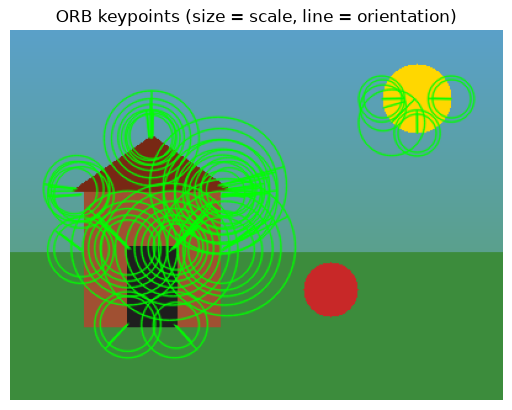

In [2]:
img = cv2.imread("../assets/test_image.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
orb = cv2.ORB_create(nfeatures=300)
keypoints, descriptors = orb.detectAndCompute(gray, None)
print("ORB keypoints:", len(keypoints), "| descriptor shape:", None if descriptors is None else descriptors.shape)
out = cv2.drawKeypoints(img, keypoints, None, (0, 255, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show(out, "ORB keypoints (size = scale, line = orientation)")

## SIFT - accurate and scale-invariant

SIFT keypoints survive scaling, rotation and moderate viewpoint change, which made SIFT the classic choice for stitching and recognition. It is slower than ORB and produces 128-float descriptors matched with L2 distance.

SIFT keypoints: 21 | descriptor shape: (21, 128)


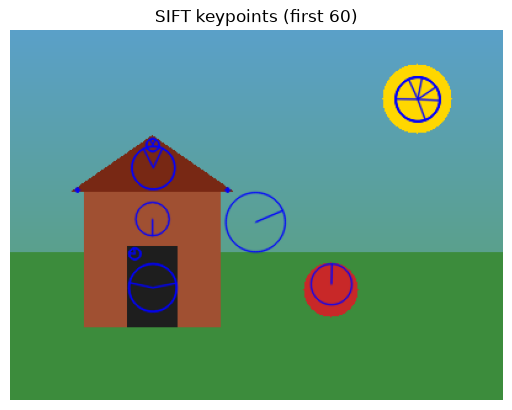

In [3]:
sift = cv2.SIFT_create()
kp_sift, des_sift = sift.detectAndCompute(gray, None)
print("SIFT keypoints:", len(kp_sift), "| descriptor shape:", None if des_sift is None else des_sift.shape)
out2 = cv2.drawKeypoints(img, kp_sift[:60], None, (255, 0, 0), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show(out2, "SIFT keypoints (first 60)")

## Brute-force matching

`cv2.BFMatcher` compares every descriptor of one image with every descriptor of the other. ORB (binary descriptors) needs NORM_HAMMING; SIFT (float descriptors) needs NORM_L2. Here we match an image against a rotated copy of itself - good matches prove the features are rotation-robust.

Cross-checked matches: 29 | best distance: 2.0


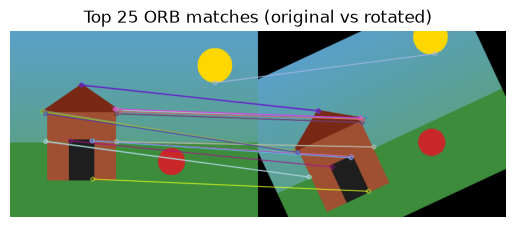

In [4]:
rotated = cv2.warpAffine(img, cv2.getRotationMatrix2D((200, 150), 25, 1.0), (400, 300))
gray_r = cv2.cvtColor(rotated, cv2.COLOR_BGR2GRAY)
kp2, des2 = orb.detectAndCompute(gray_r, None)
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = sorted(bf.match(descriptors, des2), key=lambda m: m.distance)
print("Cross-checked matches:", len(matches), "| best distance:", matches[0].distance if matches else None)
preview = cv2.drawMatches(img, keypoints, rotated, kp2, matches[:25], None, flags=2)
show(preview, "Top 25 ORB matches (original vs rotated)")

## Filtering matches: ratio test and distance cut

Raw matches contain many wrong pairs. Two standard filters: keep matches with distance below a threshold, and Lowe's ratio test with knnMatch (keep a match only if the best candidate is much better than the second best). The ratio test needs crossCheck=False.

In [5]:
bf2 = cv2.BFMatcher(cv2.NORM_HAMMING)
pairs = bf2.knnMatch(descriptors, des2, k=2)
good = []
for pair in pairs:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.75 * n.distance:
            good.append(m)
print("Matches before ratio test:", len(pairs), "| after Lowe ratio test (0.75):", len(good))

Matches before ratio test: 55 | after Lowe ratio test (0.75): 34


## Finding the object with a homography

With at least 4 good matches, `cv2.findHomography` (with RANSAC to reject outliers) computes the perspective transform between the two views. Warping the template's corners by that matrix locates the object in the scene - the core of marker and document finding.

In [6]:
if len(good) >= 4:
    src_pts = np.float32([keypoints[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask_inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    print("Homography found:", H is not None, "| inliers:", int(mask_inliers.sum()), "of", len(good))
else:
    print("Not enough good matches for a homography")

Homography found: True | inliers: 29 of 34


## ORB vs SIFT - choosing in practice

ORB: binary descriptors, very fast, free for all uses, good enough for tracking and real-time matching. SIFT: float descriptors, slower, usually more accurate under large scale/viewpoint change. Both fail on textureless surfaces (blank walls) because there is nothing distinctive to detect - features need texture.

In [7]:
print("ORB keypoints:", len(keypoints), "| SIFT keypoints:", len(kp_sift))
blank = np.full((200, 200), 255, np.uint8)
kp_blank, _ = orb.detectAndCompute(blank, None)
print("Keypoints on a blank white image:", len(kp_blank), "(no texture -> no features)")

ORB keypoints: 55 | SIFT keypoints: 21
Keypoints on a blank white image: 0 (no texture -> no features)


## Key Points

- A feature = keypoint (where) + descriptor (numeric description of the patch).
- ORB is fast and binary (NORM_HAMMING); SIFT is slower and float (NORM_L2).
- BFMatcher with crossCheck gives mutual best matches.
- Lowe's ratio test (0.75) removes most ambiguous matches.
- findHomography with RANSAC turns good matches into an object location.
- Textureless regions produce no features - features need distinctive patterns.

## Mini Task

1. Detect ORB features on `shapes.png` and print the keypoint count and descriptor shape.
2. Match `test_image.png` against a horizontally flipped copy and draw the top 20 matches.
3. Apply the ratio test at 0.6 and 0.85 and compare how many matches survive.